In [1]:
import sys
sys.path.append('..')
from image_classifier.model import get_model
import torch
import cv2
import numpy as np
from PIL import Image
import pickle
%matplotlib inline
from matplotlib import pyplot as plt
from imutils.object_detection import non_max_suppression
import scipy
from util import rotate_image

/home/yutao4/.conda/envs/torch/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model=get_model("resnet",[2,[]])
best_weight=torch.load("../results/model/ship_classifier.pth")
model.load_state_dict(best_weight)
_=model.eval()

/home/yutao4/.conda/envs/torch/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/yutao4/.conda/envs/torch/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


[2048, 2]


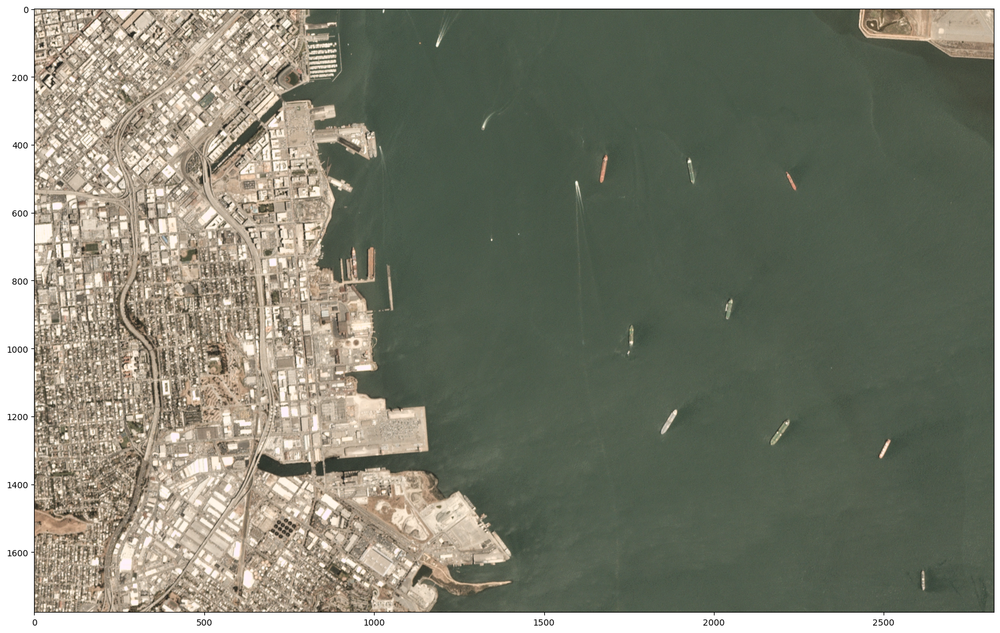

In [4]:
sample_scene=Image.open("../data/shipsnet_scenes/sfbay_1.png").convert("RGB")
sample_scene=np.array(sample_scene)
plt.figure(figsize=(20,16))
plt.imshow(sample_scene)

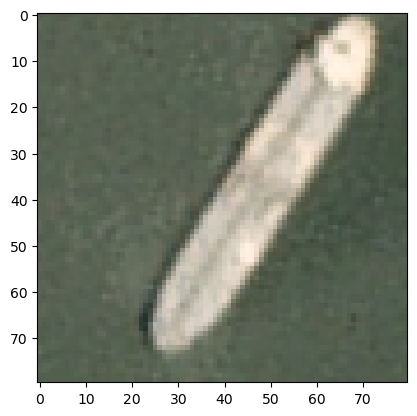

In [5]:
ship_section=sample_scene[1180:1260,1820:1900,:]
plt.imshow(ship_section)

In [6]:
batch=torch.from_numpy(np.array([ship_section.transpose(2,0,1)])).cuda().float()/255
pred=model(batch)
pred=pred.argmax(dim=1)
pred=pred.cpu().numpy()
print(pred)

[1]


In [3]:
def find_regions(image, method):
    
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(image)
    
    if method == 'fast':
        ss.switchToSelectiveSearchFast()
    else:
        ss.switchToSelectiveSearchQuality()
    
    rects = ss.process()
    boxes = []
    for (x,y,w,h) in rects:
        
        boxes.append([x,y,w,h])
        pass
    
    return boxes

In [8]:
boxes=find_regions(sample_scene, 'fast')

In [9]:
sample_scene = np.array(sample_scene, dtype=np.float32)/225
(H, W) = sample_scene.shape[:2]
rois, locs = [], []
for (x, y, w, h) in boxes:

    if w/float(W) > 0.10 and h/float(H) > 0.10:
        continue

    roi = sample_scene[y:y+h, x:x+w]
    roi = cv2.resize(roi, (80,80))
    roi = roi.transpose(2, 0, 1)
    rois.append(roi)
    locs.append((x, y, x+w, y+h))
    pass
all_rois=np.array(rois, dtype=np.float32)
all_preds=[]
# Divide the rois into batches and pass them through the model
# to get the predictions
with torch.no_grad():
    for i in range(0,len(all_rois),32):
        batch=all_rois[i:i+32]
        batch=torch.from_numpy(batch).cuda()
        output=model(batch)
        all_preds.append(output.cpu())

In [10]:
all_preds=np.concatenate(all_preds,axis=0)

In [11]:
results=np.argmax(all_preds,axis=1)

In [12]:
for (i,label) in enumerate(results):
    if label == 1:
        (x1,y1,x2,y2)=locs[i]
        cv2.rectangle(sample_scene,(x1,y1),(x2,y2),(0,255,0),2)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


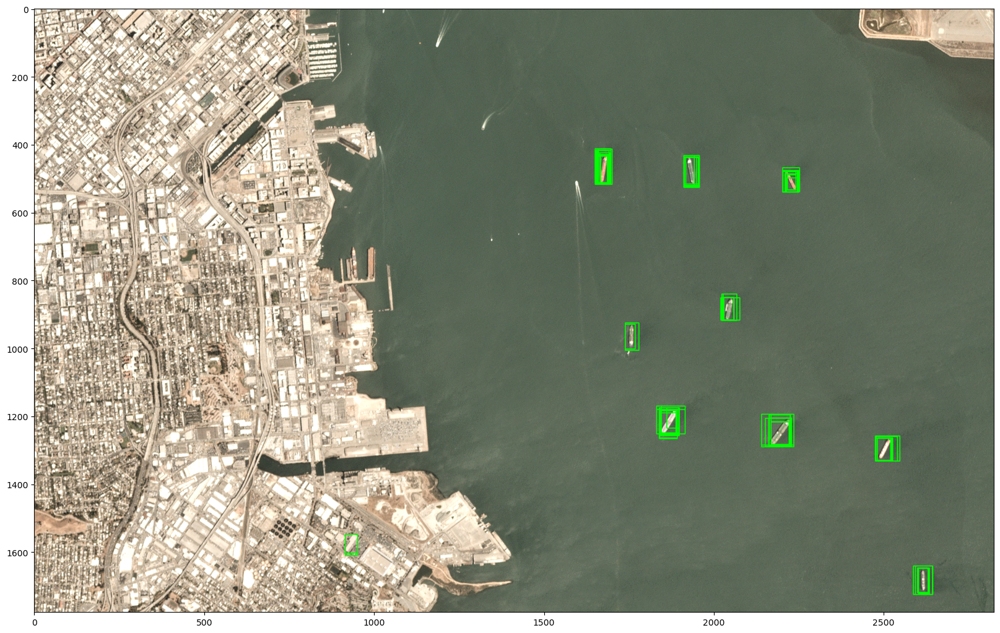

In [13]:
plt.figure(figsize=(20,16))
plt.imshow(sample_scene)

In [14]:
boxes=[]
probs=[]
for (i,label) in enumerate(results):

    if label == 1:
        boxes.append(locs[i])
        prob=scipy.special.softmax(all_preds[i])[1]
        probs.append(prob)
selected_boxes=non_max_suppression(np.asarray(boxes),probs)

In [15]:
sample_scene=Image.open("../data/shipsnet_scenes/sfbay_1.png").convert("RGB")
sample_scene=np.array(sample_scene)
for box in selected_boxes:
    (x1,y1,x2,y2)=box
    cv2.rectangle(sample_scene,(x1,y1),(x2,y2),(0,255,0),2)

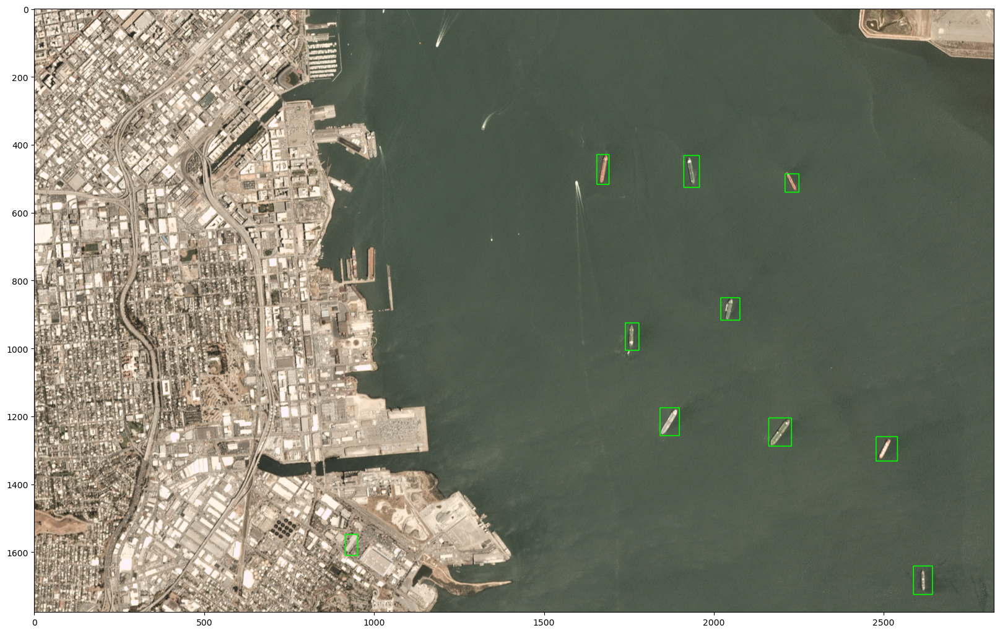

In [16]:
plt.figure(figsize=(20,16))
plt.imshow(sample_scene)

In [17]:
boxes=find_regions(sample_scene, 'quality')

(10171, 13059, 4)


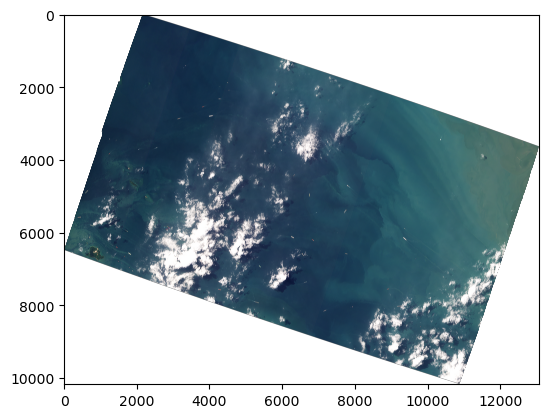

In [ ]:
img=rotate_image(img)
plt.imshow(img/255)

In [18]:
sample_scene = np.array(sample_scene, dtype=np.float32)/225
(H, W) = sample_scene.shape[:2]
rois, locs = [], []
for (x, y, w, h) in boxes:

    if w/float(W) > 0.10 and h/float(H) > 0.10:
        continue

    roi = sample_scene[y:y+h, x:x+w]
    roi = cv2.resize(roi, (80,80))
    roi = roi.transpose(2, 0, 1)
    rois.append(roi)
    locs.append((x, y, x+w, y+h))
    pass
all_rois=np.array(rois, dtype=np.float32)
all_preds=[]
# Divide the rois into batches and pass them through the model
# to get the predictions
with torch.no_grad():
    for i in range(0,len(all_rois),32):
        batch=all_rois[i:i+32]
        batch=torch.from_numpy(batch).cuda()
        output=model(batch)
        all_preds.append(output.cpu())

In [19]:
all_preds=np.concatenate(all_preds,axis=0)

In [20]:
results=np.argmax(all_preds,axis=1)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


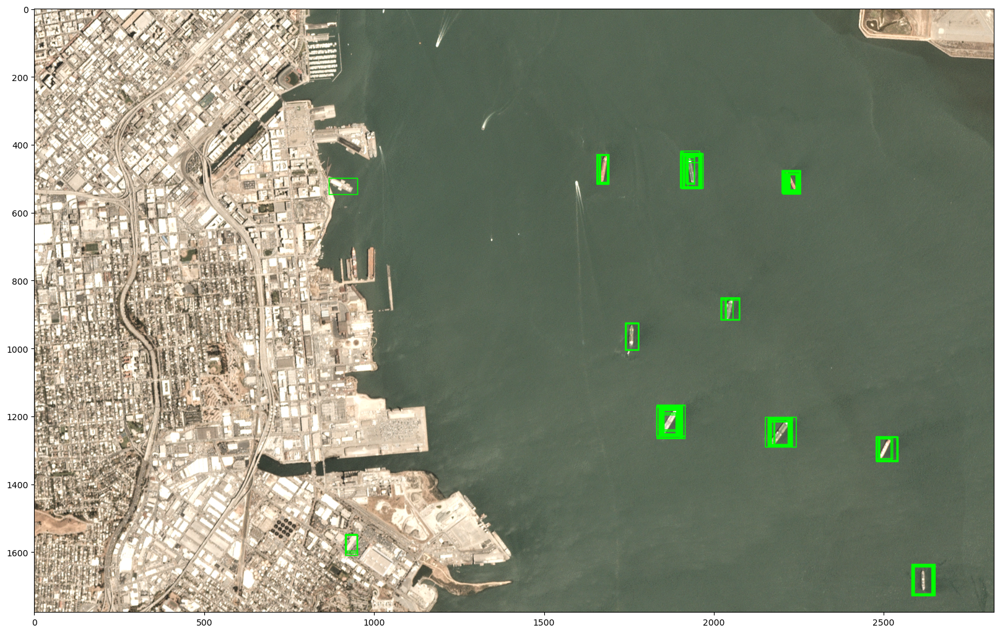

In [21]:
for (i,label) in enumerate(results):
    if label == 1:
        (x1,y1,x2,y2)=locs[i]
        cv2.rectangle(sample_scene,(x1,y1),(x2,y2),(0,255,0),2)
plt.figure(figsize=(20,16))
plt.imshow(sample_scene)

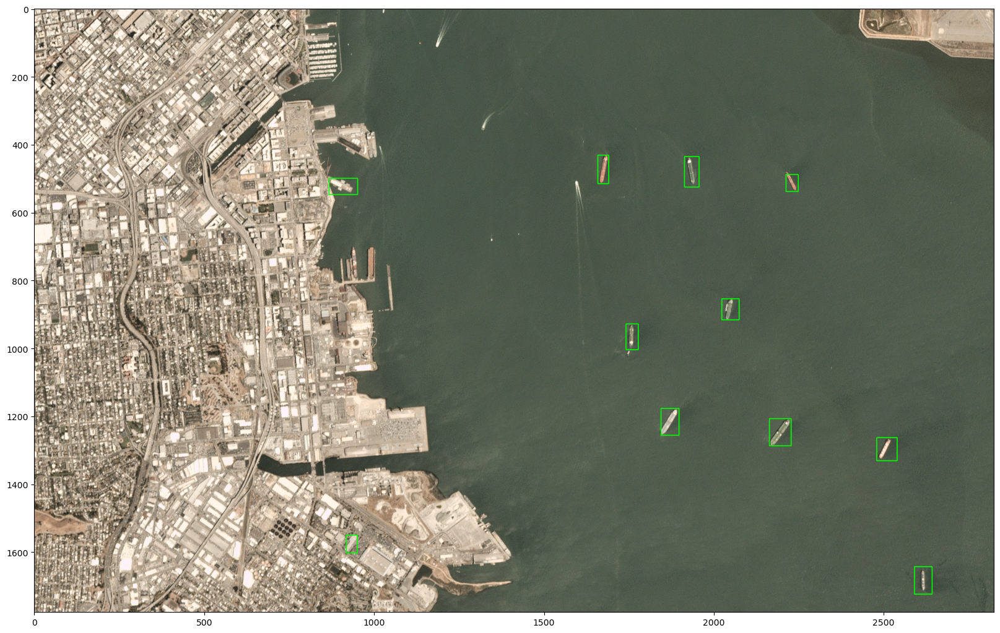

In [22]:
boxes=[]
probs=[]
for (i,label) in enumerate(results):

    if label == 1:
        boxes.append(locs[i])
        prob=scipy.special.softmax(all_preds[i])[1]
        probs.append(prob)
selected_boxes=non_max_suppression(np.asarray(boxes),probs)
sample_scene=Image.open("../data/shipsnet_scenes/sfbay_1.png").convert("RGB")
sample_scene=np.array(sample_scene)
for box in selected_boxes:
    (x1,y1,x2,y2)=box
    cv2.rectangle(sample_scene,(x1,y1),(x2,y2),(0,255,0),2)
plt.figure(figsize=(20,16))
plt.imshow(sample_scene)

In [3]:
import tifffile
sample_scene=tifffile.imread("../data/band_test/analytic/20230218_030554_61_24a3_3B_AnalyticMS_clip.tif")
sample_scene=rotate_image(sample_scene)

(6994, 11565, 4)


In [4]:
popts=pickle.load(open('../results/model/transform.pkl','rb'))
def transform(x, a, b, c):
    y =  a*np.log(x+b)+c
    y = np.clip(y,0,255)
    return y
red_function=lambda img:transform(img[:,:,2],*popts[0])
green_function=lambda img:transform(img[:,:,1],*popts[1])
blue_function=lambda img:transform(img[:,:,0],*popts[2])
transformed_image=np.stack([red_function(sample_scene),green_function(sample_scene),blue_function(sample_scene)],axis=2)

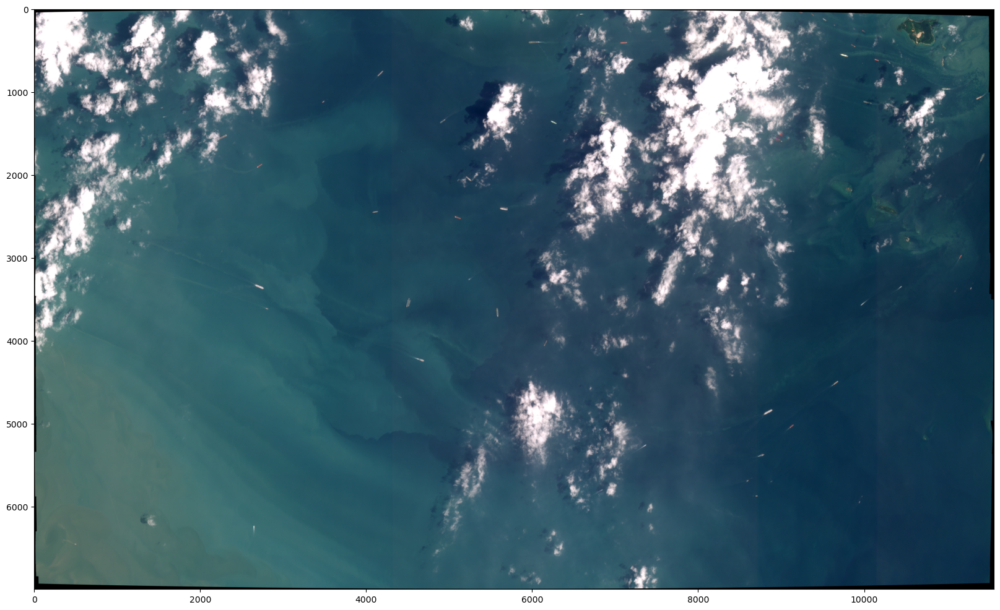

In [5]:
plt.figure(figsize=(20,16))
plt.imshow(transformed_image/255)